#Googlenet
Googlenet was the winner for the 2014 ImageNet Challenge. It introduces the use of inception modules, where instead of passing inputs to a single type of kernel (eg. 3x3, 5x5), the input can be passed through different types of layers at once.This allows the model to extract more features and concatenate them together. It is also one of the first model to make use of 1x1 kernels for dimensionality reduction.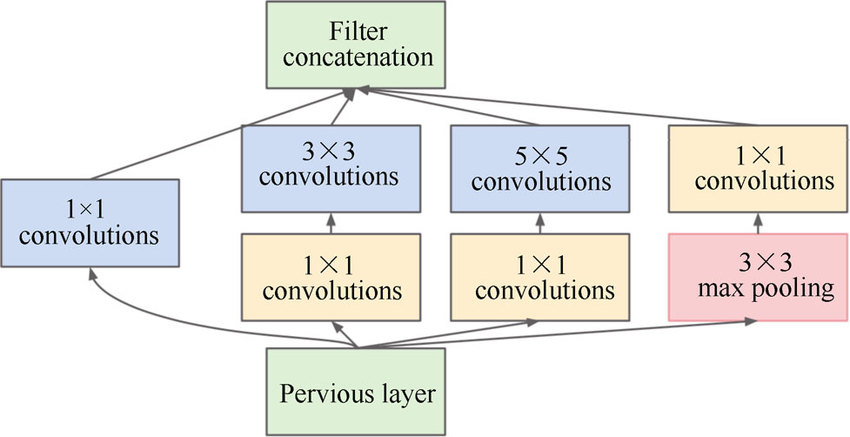


In [9]:
import tensorflow as tf
from tensorflow.keras.layers import BatchNormalization
from keras.layers.convolutional import Conv2D
from keras.layers.convolutional import AveragePooling2D
from keras.layers.convolutional import MaxPooling2D
from keras.layers.core import Activation
from keras.layers.core import Dropout
from keras.layers.core import Dense
from keras.layers import Flatten
from keras.layers import Input
from keras.models import Model
from keras.layers import concatenate
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
matplotlib.use("Agg")
%matplotlib inline
from sklearn.preprocessing import LabelBinarizer
from keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import LearningRateScheduler, ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import SGD
from keras.datasets import cifar10
import numpy as np
from keras.utils import plot_model
import os

In [2]:
#Loading in cifar10 file and splitting them into training set and test set
((trainX, trainY), (testX, testY)) = cifar10.load_data()

170498071/170498071 [==============================] - 6s 0us/step


In [3]:
#Convert values to float
trainX = trainX.astype("float")
testX = testX.astype("float")

#Since we have batch normalisation at each layer, standardization is applied to the initial input values.
#For Alexnet, our method was to divide pixel values by 255, which just lowers the range from 0-255 to 0-1. However, the spread of pixel values over the range is kept the same. Standardization helps with this issue.
trainX_mean = np.mean(trainX, axis=(0,1,2))
trainX_std = np.std(trainX, axis=(0,1,2))
trainX = (trainX - trainX_mean) / trainX_std #(input - mean)/standard deviation
testX = (testX - trainX_mean) / trainX_std

#The current values in trainY and testY are from 0-9, each corresponding to its respective classes.
#Label binarizer basically one hot encode the array, converting all to 0 except the correct index which will be a 1.
lb = LabelBinarizer()  
trainY = lb.fit_transform(trainY) 
testY = lb.transform(testY)

#Data augmentation, which generates variations of images from the dataset. This is a way to provide more training samples for the model to learn
aug = ImageDataGenerator(rotation_range=10, width_shift_range=0.1,height_shift_range=0.1, horizontal_flip=True,fill_mode="nearest")

In [4]:
#Creating the general convolution module which consists of a convolutional layer, batch normalization layer and activation layer.
#This will be used as the baseline to construct our inception module
#In order to ensure that the concatenation of outputs can be performed, the same padding is used across the module.
def conv_module(input, No_of_filters, filtersizeX, filtersizeY, stride, chanDim, padding="same"):
  input = Conv2D(No_of_filters, (filtersizeX, filtersizeY), strides = stride, padding = padding)(input)
  input = BatchNormalization(axis = chanDim)(input)
  input = Activation("relu")(input)
  return input

In [5]:
#numK refers to the number of kernels
def inception_module(input,numK1x1,numK3x3,numk5x5,numPoolProj,chanDim):
  #1x1 filters are first used to learn local features
  conv_1x1 = conv_module(input, numK1x1, 1, 1, (1, 1), chanDim) 
  
  #3x3 and 5x5 and then used to learn more complex and general features
  conv_3x3 = conv_module(input, numK3x3, 3, 3, (1, 1), chanDim) #Notice there aren't any 1x1 convolutions applied for dimensionality reduction like in the original GoogleNet. This is because cifar10 images are small enough that 
  conv_5x5 = conv_module(input, numk5x5, 5, 5, (1, 1), chanDim) #we can afford the computational resources to train the model within a reasonable amount of time without needing to reduce the channel size. This prevents loss of information
  
  #This is known as a pool projection branch. It applied 3×3 max pooling before learning features using a 1×1 convolutional layer.
  pool_proj = MaxPooling2D((3, 3), strides = (1, 1), padding = 'same')(input) 
  pool_proj = Conv2D(numPoolProj, (1, 1), padding = 'same', activation = 'relu')(pool_proj) 
  
  #Finally, feature maps from each layers are then concatenated along the channel dimension. 
  input = concatenate([conv_1x1, conv_3x3, conv_5x5, pool_proj], axis = chanDim)
  return input

In [6]:
#Downsampling/pooling module is used to prevent large amount of parameteres
#The output is the concatenation of a max-pooling layer and a convolution module with 3×3 filters
def downsample_module(input, No_of_filters, chanDim):
  conv_3x3=conv_module(input, No_of_filters, 3, 3, (2, 2), chanDim, padding = "valid")
  pool = MaxPooling2D((3, 3),strides = (2, 2))(input)
  input = concatenate([conv_3x3, pool], axis = chanDim)
  return input

In [7]:
def GoogleNet(width, height, depth, classes, dropout):
  inputShape = (height, width, depth) #Our input shape is (height, width, depth), in this case depth refers to the number of channels.
  opt = SGD(learning_rate=INIT_LR, momentum=0.9) #Setting optimizer
  chanDim=-1 #Batch samples are normalized along the channel axis(the last axis), hence the axis is set to -1. Feature maps concatenation in our inception module also uses the same axis. 
  
  #Define the model input
  inputs = Input(shape = inputShape)

  #First convolution module
  x = conv_module(inputs, 96, 3, 3, (1, 1), chanDim)

  #Two Inception modules followed by a downsample module
  x = inception_module(x, 32, 32, 32, 32, chanDim)
  x = inception_module(x, 32, 48, 48, 32, chanDim)
  x = downsample_module(x, 80, chanDim)
  
  #Five Inception modules followed by a downsample module
  x = inception_module(x, 112, 48, 32, 48, chanDim)
  x = inception_module(x, 96, 64, 32,32, chanDim)
  x = inception_module(x, 80, 80, 32,32, chanDim)
  x = inception_module(x, 48, 96, 32,32, chanDim)
  x = inception_module(x, 112, 48, 32, 48, chanDim)
  x = downsample_module(x, 96, chanDim)

  #Two Inception modules followed
  x = inception_module(x, 176, 160, 96, 96, chanDim)
  x = inception_module(x, 176, 160, 96, 96, chanDim)
  
  #Global pooling and dropout
  x = AveragePooling2D((7, 7))(x)
  x = Dropout(dropout)(x)

  #Softmax classifier
  x = Flatten()(x)
  x = Dense(classes)(x)
  x = Activation("softmax")(x)

  #Create the model
  model = Model(inputs, x, name="googlenet")
  
  #Compiling model
  model.compile(loss="categorical_crossentropy", optimizer=opt,metrics=["accuracy"]) 
  return model

In [8]:
INIT_LR = 5e-4 #Initialising learning rate
NUM_EPOCHS = 10 #Set number of epochs
model = GoogleNet(width=32, height=32, depth=3, classes=10, dropout=0.5) #Call model

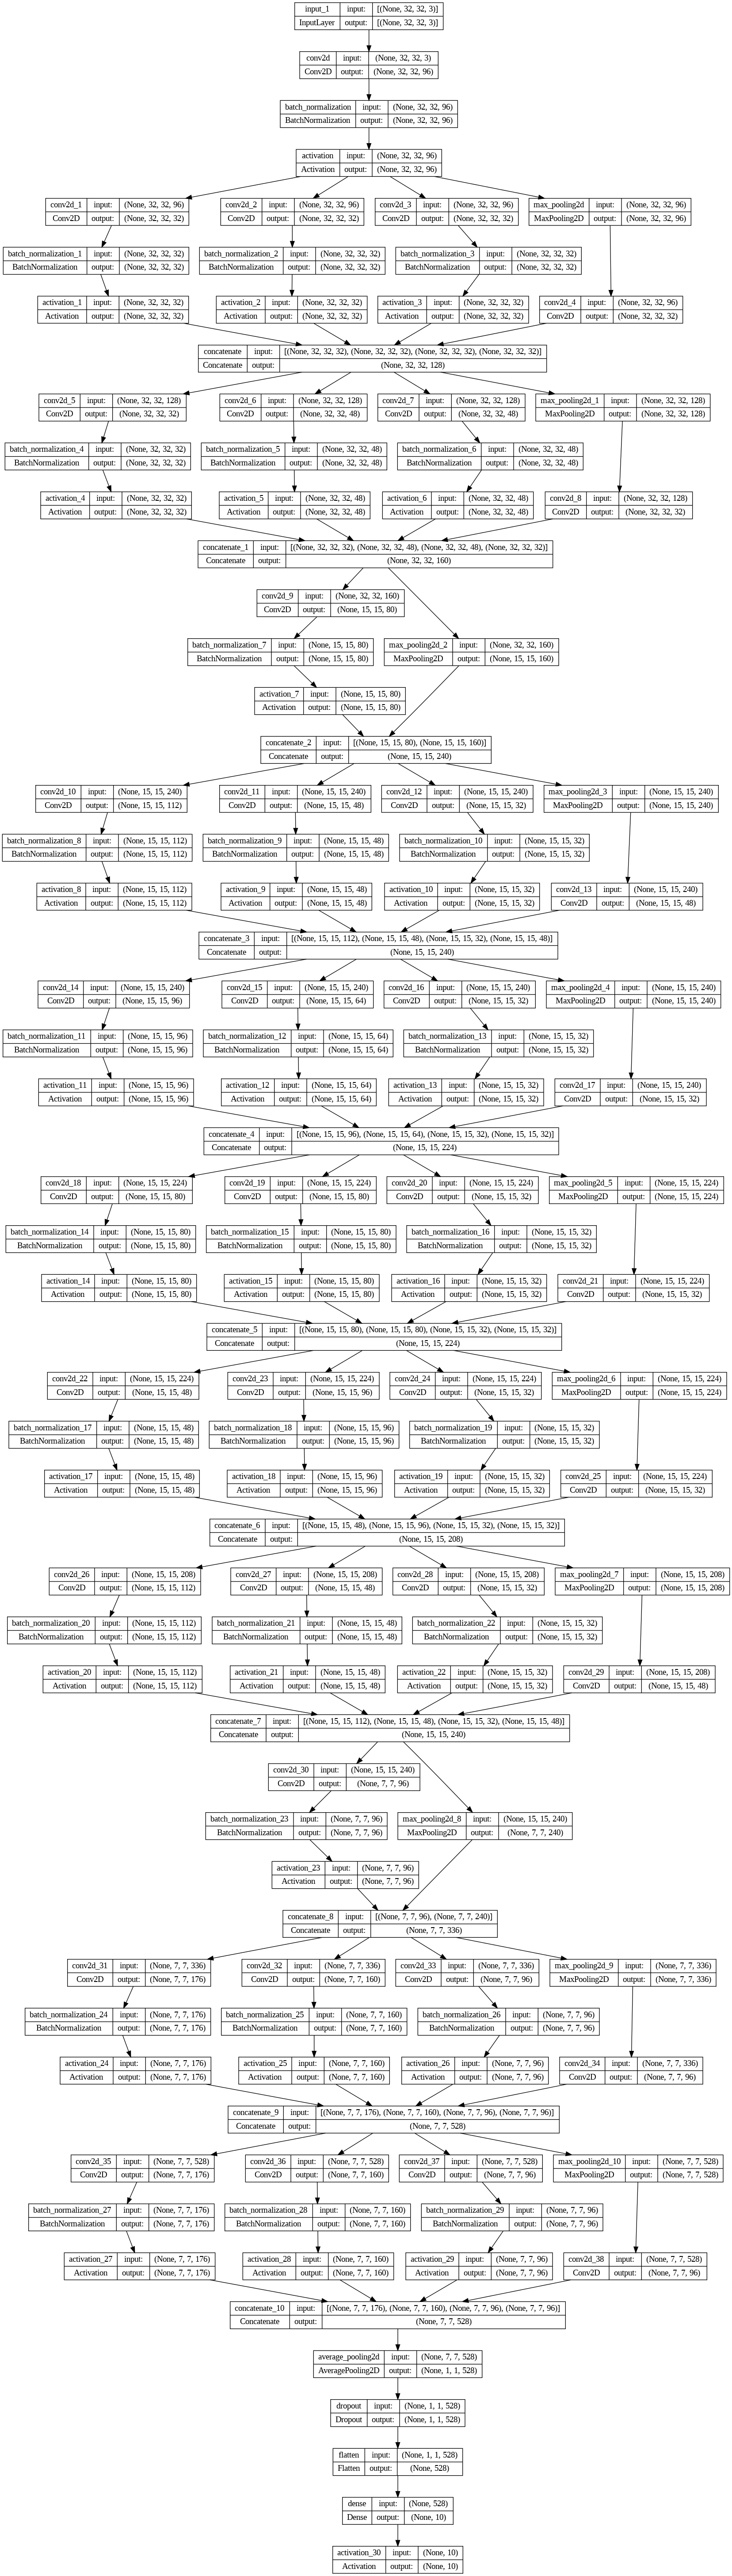

In [10]:
plot_model(model, to_file = "googlenet_cifar10_architecture.png", show_shapes = True)

In [ ]:
#Fitting model
GoogLeNet_history = model.fit(aug.flow(trainX, trainY, batch_size = 64),validation_data = (testX, testY), steps_per_epoch = len(trainX) // 64, epochs = NUM_EPOCHS, verbose = 1)

Epoch 1/10
781/781 [==============================] - 143s 151ms/step - loss: 1.6363 - accuracy: 0.4000 - val_loss: 1.3921 - val_accuracy: 0.5081
Epoch 2/10
781/781 [==============================] - 118s 150ms/step - loss: 1.2516 - accuracy: 0.5506 - val_loss: 1.2257 - val_accuracy: 0.5756
Epoch 3/10
781/781 [==============================] - 117s 150ms/step - loss: 1.0785 - accuracy: 0.6128 - val_loss: 1.0635 - val_accuracy: 0.6193
Epoch 4/10
781/781 [==============================] - 113s 145ms/step - loss: 0.9736 - accuracy: 0.6584 - val_loss: 1.0330 - val_accuracy: 0.6434
Epoch 5/10
781/781 [==============================] - 117s 150ms/step - loss: 0.8946 - accuracy: 0.6853 - val_loss: 1.0402 - val_accuracy: 0.6425
Epoch 6/10
781/781 [==============================] - 117s 150ms/step - loss: 0.8202 - accuracy: 0.7115 - val_loss: 0.9143 - val_accuracy: 0.6825
Epoch 7/10
781/781 [==============================] - 117s 150ms/step - loss: 0.7756 - accuracy: 0.7307 - val_loss: 0.9380 -

In [ ]:
#Print evaluation results
score=model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 7s 22ms/step - loss: 0.7825 - accuracy: 0.7329
Test Score= 0.7825381755828857
Test Accuracy= 0.7329000234603882


In [ ]:
#Create a function to fit in bayesian optimization
def fit_with(batch_size, dropout):
    model = GoogleNet(width=32, height=32, depth=3, classes=10, dropout=dropout) 

    #Fitting model. Notice that batch_size is replaced as a variable since this is what we want to optimize and find the best value for. Same thing is applied for dropout
    model.fit(aug.flow(trainX, trainY, batch_size = round(batch_size)),validation_data = (testX, testY), steps_per_epoch = round(len(trainX) // batch_size), epochs = NUM_EPOCHS, verbose = 0)

    #Evaluate model
    score=model.evaluate(testX, testY)
    print('Test loss:', score[0])
    print('Test accuracy:', score[1])

    #Return the accuracy
    return score[1]

In [ ]:
from bayes_opt import BayesianOptimization
bounds ={
    'batch_size':(32, 256),
    'dropout':(0.3, 0.7)
}
optimizer = BayesianOptimization(fit_with, bounds, random_state = 1, verbose = 2)
optimizer.maximize(init_points=2, n_iter=3)

for i, res in enumerate(optimizer.res):
    print("Iteration {}: \n\t{}".format(i, res))

|   iter    |  target   | batch_... |  dropout  |
-------------------------------------------------
313/313 [==============================] - 7s 21ms/step - loss: 0.8054 - accuracy: 0.7201
Test loss: 0.8053869605064392
Test accuracy: 0.7200999855995178
| 1         | 0.7201    | 125.4     | 0.5881    |
313/313 [==============================] - 6s 20ms/step - loss: 0.6135 - accuracy: 0.7892
Test loss: 0.6134925484657288
Test accuracy: 0.7892000079154968
| 2         | 0.7892    | 32.03     | 0.4209    |
313/313 [==============================] - 6s 20ms/step - loss: 0.7049 - accuracy: 0.7703
Test loss: 0.7048602104187012
Test accuracy: 0.7702999711036682
| 3         | 0.7703    | 33.34     | 0.4434    |
313/313 [==============================] - 7s 21ms/step - loss: 1.0916 - accuracy: 0.6379
Test loss: 1.0916484594345093
Test accuracy: 0.6378999948501587
| 4         | 0.6379    | 217.9     | 0.5641    |
313/313 [==============================] - 6s 21ms/step - loss: 0.8563 - accuracy: 0

In [ ]:
#Print out the best parameters
print(optimizer.max)

{'target': 0.7892000079154968, 'params': {'batch_size': 32.025619959085255, 'dropout': 0.4209330290527359}}


In [ ]:
#Setting checkpoint path and directory to store model
checkpoint_path = "training_2/cp-{epoch:04d}.ckpt"
checkpoint_dir = os.path.dirname(checkpoint_path)

In [ ]:
#Creating a model checkpoint that saves the model weights and configuration after every epoch
checkpoint = ModelCheckpoint(filepath=checkpoint_path,
                             monitor='accuracy',
                             verbose=1)

#Stop model from continuing when the validation accuracy does not increase after 25 continuous epochs. 
#The model will then restore model weights from the epoch with the best validation accuracy
early_stopping = EarlyStopping(monitor='val_accuracy', mode='max', verbose=0, patience=25, restore_best_weights = True)

In [ ]:
#This is just to get rid of some of the warning raised when calling too many functions within a model. 
import absl.logging
absl.logging.set_verbosity(absl.logging.ERROR)

In [ ]:
#Learning rate decay function, which decay/reduces the learning rate after each epoch in a polynomial manner.
#The point of this is to avoid the model from oscillating too far away from the minima during the backpropagation gradient descent process.
def poly_decay(epoch):
  maxEpochs = NUM_EPOCHS
  baseLR = INIT_LR
  power = 1.0
  alpha = baseLR * (1 - (epoch / float(maxEpochs))) ** power
  return alpha

In [ ]:
#Initialize the number of epochs and the initial learning rate.
NUM_EPOCHS = 120
INIT_LR = 5e-3
dropout = 0.4
batch_size = 32
callbacks=[checkpoint, early_stopping, LearningRateScheduler(poly_decay)]

optimized_model = GoogleNet(width=32, height=32, depth=3, classes=10, dropout=dropout) 
GoogLeNet_history = optimized_model.fit(aug.flow(trainX, trainY, batch_size = batch_size),validation_data = (testX, testY), steps_per_epoch = len(trainX) // batch_size, epochs = NUM_EPOCHS, verbose = 1, callbacks = callbacks)

Epoch 1/120
1562/1562 [==============================] - ETA: 0s - loss: 1.3472 - accuracy: 0.5136
Epoch 1: saving model to training_2/cp-0001.ckpt
1562/1562 [==============================] - 148s 89ms/step - loss: 1.3472 - accuracy: 0.5136 - val_loss: 1.4218 - val_accuracy: 0.5205 - lr: 0.0050
Epoch 2/120
1562/1562 [==============================] - ETA: 0s - loss: 0.9023 - accuracy: 0.6858
Epoch 2: saving model to training_2/cp-0002.ckpt
1562/1562 [==============================] - 148s 95ms/step - loss: 0.9023 - accuracy: 0.6858 - val_loss: 1.0116 - val_accuracy: 0.6676 - lr: 0.0050
Epoch 3/120
1562/1562 [==============================] - ETA: 0s - loss: 0.7352 - accuracy: 0.7472
Epoch 3: saving model to training_2/cp-0003.ckpt
1562/1562 [==============================] - 146s 93ms/step - loss: 0.7352 - accuracy: 0.7472 - val_loss: 0.8375 - val_accuracy: 0.7235 - lr: 0.0049
Epoch 4/120
1562/1562 [==============================] - ETA: 0s - loss: 0.6384 - accuracy: 0.7800
Epoch 4: s

In [ ]:
optimized_model.save('googlenet.keras')

In [ ]:
score=optimized_model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 6s 21ms/step - loss: 0.3931 - accuracy: 0.9229
Test Score= 0.39309608936309814
Test Accuracy= 0.9229000210762024


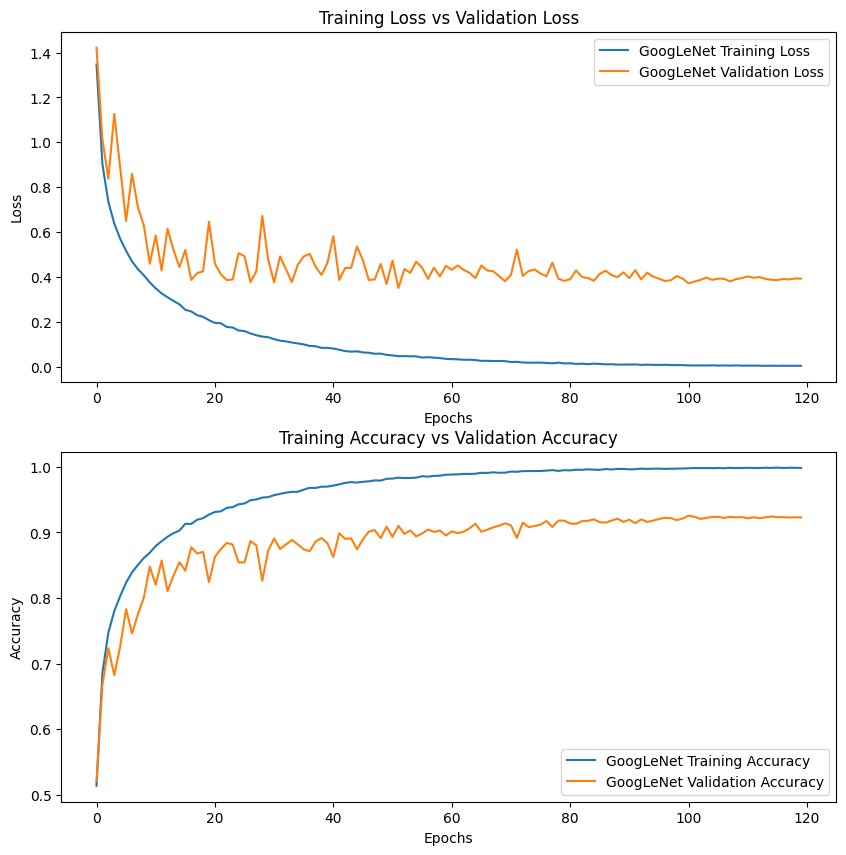

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(10,10))

axs[0].plot(GoogLeNet_history.history['loss'])
axs[0].plot(GoogLeNet_history.history['val_loss'])

axs[0].title.set_text('Training Loss vs Validation Loss')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend(['GoogLeNet Training Loss', 'GoogLeNet Validation Loss'])

axs[1].plot(GoogLeNet_history.history['accuracy'])
axs[1].plot(GoogLeNet_history.history['val_accuracy'])
axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend(['GoogLeNet Training Accuracy', 'GoogLeNet Validation Accuracy'])

In [ ]:
pred = optimized_model.predict(testX)

313/313 [==============================] - 7s 19ms/step


In [ ]:
from sklearn.metrics import classification_report
y_pred = np.argmax(pred, axis=1)
y_true = np.argmax(testY, axis=1)
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93      1000
           1       0.96      0.97      0.97      1000
           2       0.90      0.90      0.90      1000
           3       0.88      0.82      0.85      1000
           4       0.92      0.91      0.92      1000
           5       0.92      0.85      0.88      1000
           6       0.89      0.97      0.93      1000
           7       0.95      0.95      0.95      1000
           8       0.96      0.95      0.95      1000
           9       0.94      0.96      0.95      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



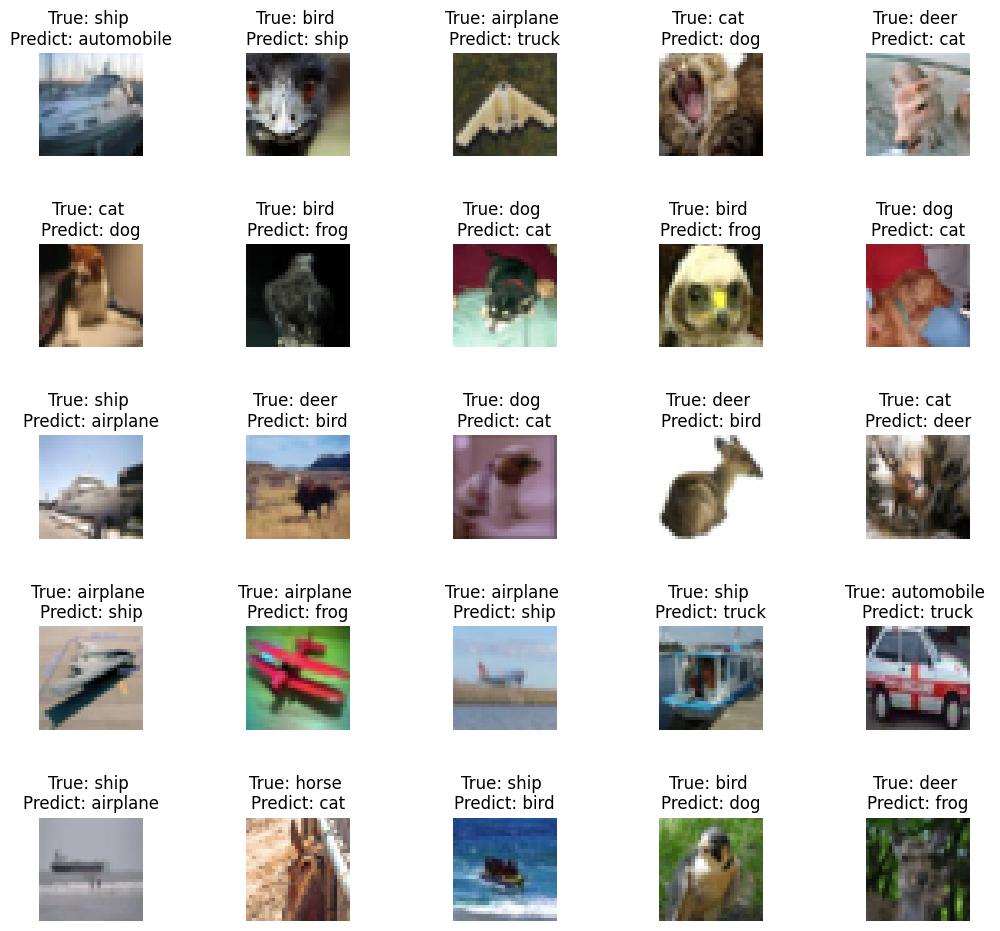

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(12,12))
axes = axes.ravel()
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

#Revert images back to their original form before standardization
trainX = (trainX * trainX_std) + trainX_mean 
testX = (testX * trainX_std) + trainX_mean

miss_pred = np.where(y_pred != y_true)[0]
for i in np.arange(25): 
    axes[i].imshow(testX[miss_pred[i]].astype('uint8'))
    axes[i].set_title('True: %s \nPredict: %s' % (class_names[y_true[miss_pred[i]]], class_names[y_pred[miss_pred[i]]]))
    axes[i].axis('off')
    plt.subplots_adjust(wspace=1)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
confusion_matrix = tf.math.confusion_matrix(labels=y_true, predictions=y_pred)
confusion_matrix = confusion_matrix.numpy()

Text(0.5, 1.0, 'Confusion Matrix')

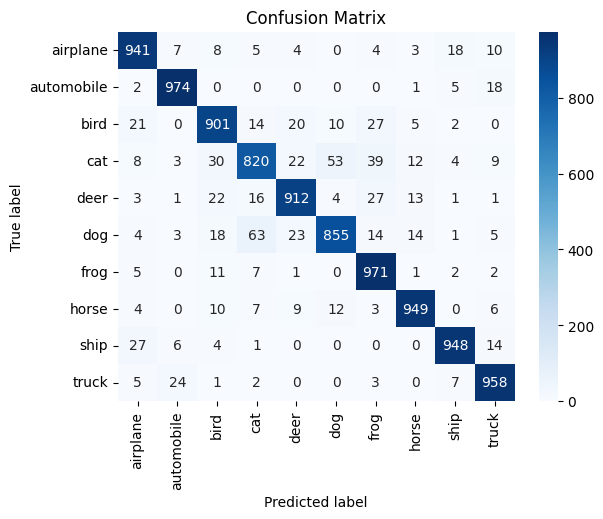

In [ ]:
sns.heatmap(confusion_matrix, annot=True, fmt="g", xticklabels = class_names, yticklabels = class_names, cmap=plt.cm.Blues)
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix')

In [ ]:
#Convert the model
converter = tf.lite.TFLiteConverter.from_keras_model(optimized_model)
tflite_model = converter.convert()

#Save the model
with open('GoogleNet.tflite', 'wb') as f:
  f.write(tflite_model)